# Tarea 04: Expresiones simbólicas

**Semana 4** · Entrega: antes de la clase de la Semana 5

## Objetivos de la tarea

1. Declarar símbolos con las suposiciones que exige el problema físico.
2. Construir una expresión simbólica y sustituir valores en ella con `subs`.
3. Decidir si dos expresiones son matemáticamente equivalentes, y no solo
   estructuralmente iguales.

In [32]:
#Importamos las librerías
import sympy as sp

sp.init_printing()

## Ejercicio 1 (caso base)

El **factor de Lorentz** y la energía total de una partícula relativista son

$$\gamma = \frac{1}{\sqrt{1 - \dfrac{v^2}{c^2}}}
\qquad
E = \gamma\, m\, c^2$$

Completa la celda de abajo con estos nombres exactos, que son los que usa
`tests/test_tarea.py` para calificar:

- `masa`, `rapidez` y `velocidad_luz`: los tres símbolos del problema. Sus
  **nombres de símbolo** deben ser exactamente `"m"`, `"v"` y `"c"` — que
  no son los nombres de las variables de Python, como vimos en la sesión 1.
  Declara las suposiciones que la física garantiza: la masa y $c$ son
  positivas, la rapidez es real.
- `factor_lorentz`: la expresión de $\gamma$.
- `energia_total`: la expresión de $E$, construida a partir de
  `factor_lorentz`.
- `energia_en_reposo`: el valor de `energia_total` cuando la partícula está
  quieta, obtenido **con `subs`** (no lo escribas a mano). Debe salirte
  $m c^2$.
- `factor_a_media_luz`: el valor de `factor_lorentz` cuando $v = c/2$,
  simplificado. Debe quedarte una expresión exacta con una raíz, no un
  número decimal.

Cuida las fracciones: `1/2` es un flotante y contamina la expresión;
`sp.Rational(1, 2)` no. Lo mismo con la raíz — usa `sp.sqrt`, no `**0.5`.

In [33]:
# TODO: completa el ejercicio 1

#Parte 1.- definimos las variables simbólicas
masa = sp.symbols("m", positive=True)
rapidez = sp.symbols("v", real=True)
velocidad_luz = sp.symbols("c", positive=True)

In [34]:
#Imprimimos las variables para asegurarnos de que las definí bien
print(masa)
print(rapidez)
print(velocidad_luz)

m
v
c


In [35]:
#Parte 2.- Definimos el factor de Lorentz
factor_lorentz = 1/(sp.sqrt(1-(rapidez**2/velocidad_luz**2)))

#Parte 3.- Definimos la expresión de la energía total
energia_total = factor_lorentz*masa*velocidad_luz**2

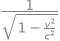

In [36]:
factor_lorentz

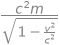

In [37]:
energia_total

In [38]:
#Parte 4.- Definimos la energía en reposo
#Si la partícula está en reposo, entonces v=0; reemplazamos v con 0
energia_en_reposo = energia_total.subs(rapidez, 0)
energia_en_reposo

In [39]:
#Parte 5.- reemplazamos la v con c/2
factor_a_media_luz = factor_lorentz.subs(rapidez, sp.Rational(1,2)*velocidad_luz)
factor_a_media_luz

## Ejercicio 2 (caso límite)

En la sesión 1 vimos que `==` compara **estructura**, no matemáticas.
Escribe la función que sí compara matemáticas:

```python
son_equivalentes(expresion_a, expresion_b)
```

Devuelve `True` si las dos expresiones son matemáticamente equivalentes, y
`False` si no. Reglas:

1. **No uses `==` entre las dos expresiones.** Compara su diferencia, con
   la receta de clase: `sp.simplify(expresion_a - expresion_b) == 0`.
2. Si esa vía no decide, apóyate en `.equals()`, que además prueba
   numéricamente.
3. El resultado tiene que ser un `bool` de Python — `True` o `False`, nunca
   `None` ni un objeto de SymPy. Ojo aquí: `.equals()` puede devolver
   `None`, que significa *"no lo sé"* (la lógica de tres valores de la
   sesión 1). Cuando SymPy no logre decidir, tu función debe responder
   `False`.

Un aviso sobre el punto 3, porque es lo que distingue este ejercicio del
anterior: la respuesta correcta **depende de las suposiciones** de los
símbolos. Con `x` genérica, $\sqrt{x^2}$ y $x$ **no** son equivalentes —si
$x$ fuera negativa serían distintas—; con `x` positiva, sí lo son. Tu
función no tiene que arreglar eso: tiene que respetarlo, que es lo que pasa
sola si le dejas la decisión a SymPy en lugar de tomarla tú.

In [40]:
# TODO: completa el ejercicio 2

#Vamos a definir la expresión que va a comparar dos expresiones; vamos a utilizar la energía total y el factor de Lorentz
def son_equivalentes(expresion_a, expresion_b):
    """Indica si dos expresiones de SymPy son matematicamente equivalentes."""
    return sp.simplify(expresion_a - expresion_b) == 0
   


In [41]:
#Verificamos si el factor de Lorentz y la energía total son equivalentes
son_equivalentes(factor_lorentz, energia_total)

False

In [42]:
#Multiplicamos al factor de Lorentz por m y c**2
son_equivalentes(factor_lorentz*masa*velocidad_luz**2, energia_total)

True

## Resumen

Entrega esta tarea por **Pull Request dentro de tu fork**, como la de la
semana 3. El paso a paso está en
[`docs/git-guia.md`](../../docs/git-guia.md), y el checklist completo en
[`README.md`](README.md).

Antes de entregar, corre el notebook desde un kernel limpio
(`Kernel → Restart & Run All`) y confirma que llega hasta el final sin
errores. Al hacer push, GitHub Actions corre los tests y deja un check
✅ o ❌ en tu Pull Request.